In [ ]:
# 그래프 관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 판다스 관련 import
import pandas as pd
import numpy as np

# 인공지능 import
from sklearn import svm,metrics # 분류와 숫자 예측에 사용하는 모델 모음,모델의 예측 성능을 평가하는 도구 모음
from sklearn.neighbors import KNeighborsClassifier  #분류(가까운 이웃 데이터를 참고해 종류를 분류)
from sklearn.neighbors import KNeighborsRegressor   #예측(가까운 이웃데이터를 참고해 숫자를 예측)

from sklearn.preprocessing import PolynomialFeatures # 다항특성 (x², x₁ × x₂ 같은 특성을 추가)
from sklearn.preprocessing import OneHotEncoder      # 원핫인코딩(문자형 번주를 0과1로 변환)
from sklearn.preprocessing import StandardScaler # 표준화 (각 특성을 평균 0, 표준편차 1 기준으로 표준화)

from sklearn.linear_model import LinearRegression   #예측 (입력과 결과의 선형관례를 학습해 숫자를 예측)
from sklearn.linear_model import Ridge              #릿지 (계수가 지나치게 커지는 것을 억제하는 선형 회귀)
from sklearn.linear_model import Lasso              #라쏘 (일부 계수를 0으로 만들어 특성 선택에도 활용하는 선형 회귀)
from sklearn.linear_model import LogisticRegression #분류
from sklearn.linear_model import SGDClassifier

from sklearn.tree import DecisionTreeClassifier     #결정트리

from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위 (실제값과 예측값의 차이를 절댓값으로 구한 뒤 평균 계산)
from sklearn.model_selection import train_test_split #(데이터를 학습용과 평가용으로 분리)
from scipy.special import expit                     #exip:이진분류함수
from scipy.special import softmax                   #softmax: 다중분류함수

In [9]:
df = pd.read_csv('data/wine.csv')
df.head(2)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [10]:
data= df[df.columns[:-1]].values
lable= df['class'].values

train_data, test_data, train_label, test_label = train_test_split(data, lable, stratify=lable, random_state=42)

In [11]:
# 정규화 작업
ss= StandardScaler()
ss.fit(train_data)

train_scaled= ss.transform(train_data)
test_scaled= ss.transform(test_data)

In [14]:
# lr = LogisticRegression()
# sc=  SGDClassifier(): 분류
# loss='log_loss': lr = LogisticRegression()에 있는 log함수를 사용한다.
# max_iter=10 : 10번 반복
# random_state=42 : 랜덤선택을 고정 ( 실제 테스트때는 없어야함, 연습할 때 랜덤을 변경하면 정확도도 함께 변경되어서 고정한것.)
# verbose=1 : 반복할 때 정보를 보여줌. / 설정하지 않으면 보여주지 않음.


sc=  SGDClassifier(loss='log_loss', tol=None ,random_state=42)

# 정확도 값 추가
train_score=[]
test_score=[]

# 정답지 필요 : sc.partial_fit(train_scaled, train_label)를 먼저 안했기에 필요
classes = np.unique(train_label) #/ train_unique()와 같음.

for i in range(300):
    sc.partial_fit(train_scaled, train_label, classes=classes)
    train_score.append(sc.score(train_scaled, train_label))
    test_score.append(sc.score(test_scaled, test_label))

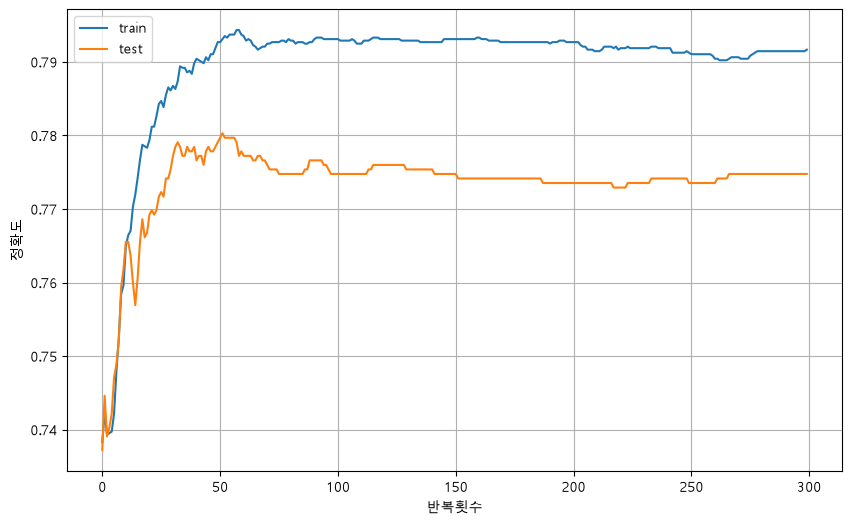

In [13]:
plt.figure(figsize=(10,6)) # 그래프 확대

plt.plot(train_score)
plt.plot(test_score)

plt.xlabel('반복횟수')
plt.ylabel('정확도')

plt.legend(['train','test'])
plt.grid()

plt.show()

In [15]:
# tol=None : max_iter 반복할 때 일정기간동안 변동이 없으면 자동으로 중지하는데 자동중지 해제

sc= SGDClassifier(loss='log_loss', max_iter=50, tol=None, random_state=42)
sc.fit(train_scaled, train_label)
print('train정확도:', sc.score(train_scaled, train_label))
print('test정확도:', sc.score(test_scaled, test_label))

train정확도: 0.7875615763546798
test정확도: 0.7753846153846153
